# 07d — Survival Model

In [1]:
# Cell 1 — setup
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent / "src"))
from scorelab import config, data
con = data.connect()            # read-only DuckDB connection to data/lc.duckdb

In [2]:
# Cell 2 — sanity check
print(con.sql("SHOW TABLES"))
print(con.sql("SELECT COUNT(*) AS n, MIN(issue_d), MAX(issue_d) FROM accepted"))

┌─────────────────┐
│      name       │
│     varchar     │
├─────────────────┤
│ accepted        │
│ rejected        │
│ v_accepted_asof │
│ v_split         │
│ v_target        │
└─────────────────┘

┌─────────┬──────────────┬──────────────┐
│    n    │ min(issue_d) │ max(issue_d) │
│  int64  │     date     │     date     │
├─────────┼──────────────┼──────────────┤
│ 2260668 │ 2007-06-01   │ 2018-12-01   │
└─────────┴──────────────┴──────────────┘



In [3]:
# Cell 3 — common imports and settings for this notebook
import json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
from scorelab import target, attributes as A, binning as B, scorecard as S, validation as V, fairness as F
from scorelab import challengers as C, reject_inference as R, monitoring as M, report as REP
from scorelab import tuning as T, explain as E, survival as SV, causal as CA
MODELS = config.MODELS_DIR; MODELS.mkdir(exist_ok=True)
SAMPLE_FRAC = None     # None = full data (recommended for the fitting notebooks); e.g. 0.10 for a quick pass
cols = [r[0] for r in con.execute("DESCRIBE v_target").fetchall()]
assert "label" in cols, "v_target is the old stub: close this kernel and run `python scripts/refresh_views.py`"
def load_frame(splits=("train", "validate", "oot"), **kw):
    """Observable, non-excluded loans with attributes built; indeterminates dropped unless asked."""
    f = target.modeling_frame(con, splits=splits, sample_frac=SAMPLE_FRAC, **kw)
    return A.build_attributes(f)
MEANINGS = {a.name: a.meaning for a in A.REGISTRY}
DIRECTIONS = {a.name: a.direction for a in A.REGISTRY}

## What this notebook settles

Whether modelling *when* a loan defaults adds anything to the card's *whether*. A discrete-time hazard (multinomial logit by months on book, with prepayment as a competing risk) is fitted on the training vintages with the card's WOE attributes as covariates. Its cumulative incidence of default at month 24 is the probability of the label event, so it compares directly with the card's PD on 2016; its curves show *how* each score band's defaults accumulate.

Timing comes from the same reconstruction as the label (90+ DPD = last payment + 4 months), so the hazard inherits that approximation: it cannot see a cure, and a charge-off's timing is only as good as its last payment date.

Decisions: **AA — the hazard specification** (baseline bands, covariates, prepayment treatment), **AB — what the comparison means for the card**.

In [4]:
frame = SV.event_times(SV.event_frame(con, load_frame(include_indeterminate=True)))
card, specs = S.load_card(MODELS / "champion"); card_attrs = card.attributes
cov = [a + "_woe" for a in card_attrs]
frame = frame.join(B.transform_woe(frame, {a: specs[a] for a in card_attrs}))
tr, oot = frame[frame.split == "train"], frame[frame.split == "oot"]
display(pd.crosstab(frame.label, frame.exit_type, margins=True))      # default exactly when label == bad

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

exit_type,censored,default,prepay,All
label,,,,
bad,0,133001,0,133001
good,683841,0,381334,1065175
indeterminate,18469,0,0,18469
All,702310,133001,381334,1216645


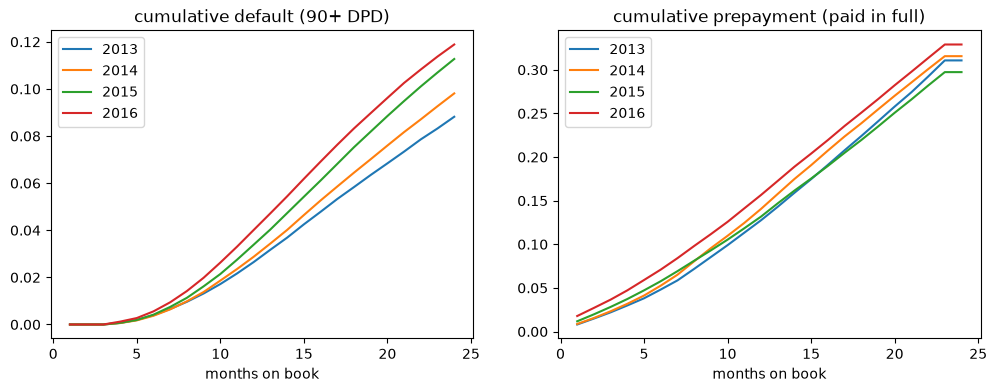

In [5]:
# Evidence — observed cumulative incidence of default and prepayment by vintage (Aalen-Johansen)
emp_v = SV.empirical_cif(frame, group="vintage_year")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for y, d in emp_v.groupby("vintage_year"):
    axes[0].plot(d.month, d.cif_default, label=y); axes[1].plot(d.month, d.cif_prepay, label=y)
axes[0].set_title("cumulative default (90+ DPD)"); axes[1].set_title("cumulative prepayment (paid in full)")
for ax in axes: ax.set_xlabel("months on book"); ax.legend()
plt.show()

### Decision AA — Hazard specification

Baseline: piecewise-constant in 3-month bands (the default) or monthly? Covariates: the card's WOE attributes only (a like-for-like comparison) or more? Prepayment: a competing risk (the CIF then matches the label) or censoring (the "if nobody prepaid" default probability, always higher)? How many loans to expand (each contributes up to 24 rows)?

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**Keep the defaults:** a piecewise-constant baseline in 3-month bands, the card's 8 WOE attributes as covariates, prepayment as a competing risk, and 150,000 training loans.

- **Data:** 150,000 loans expand to 2,984,190 person-months, with 14,166 defaults and 46,986 prepayments. That is enough events for 8 bands and 8 covariates per outcome.
- **The baseline moves a lot between bands,** so monthly steps would add parameters without changing the shape:
  - default log-hazard rises from −7.50 (months 1–3) to −4.76 (months 22–24);
  - prepayment log-hazard rises from −4.88 to −3.70 (months 19–21).
- **Prepayment must stay a competing risk.** On the labelled loans 381,334 prepaid against 133,001 defaults, so treating prepayment as censoring would describe a population that does not exist.
- **The covariates act differently on the two outcomes.**
  - All 8 lower the default hazard as WOE rises (−0.32 to −0.75).
  - For prepayment, `percent_bc_gt_75` (+0.63) and `bal_ex_mort_to_limit` (+0.20) raise it, while `num_tl_op_past_12m` (−0.42) and `mths_since_recent_inq` (−0.30) lower it.
  - Low-utilisation borrowers prepay more; recently active borrowers prepay less.

In [6]:
HAZARD_SAMPLE = 150_000                     # training loans expanded to person-months
BANDS = SV.month_bands((3, 6, 9, 12, 15, 18, 21, 24))
trs = tr.sample(min(HAZARD_SAMPLE, len(tr)), random_state=42)
pp = SV.person_period(trs, cov)
print(f"{len(trs):,} loans -> {len(pp):,} person-months; outcomes:", pp.outcome.value_counts().to_dict())
hm = SV.HazardModel(cov, bands=BANDS).fit(pp)
base, coefs = hm.baseline_table(); display(base); display(coefs)

150,000 loans -> 2,984,190 person-months; outcomes: {0: 2923038, 2: 46986, 1: 14166}


,months,default_coef,prepay_coef
0,1-3,-7.4964,-4.8794
1,4-6,-6.7285,-4.6114
2,7-9,-5.8181,-4.2059
3,10-12,-5.2729,-4.0846
4,13-15,-4.9616,-3.8665
5,16-18,-4.8763,-3.7949
6,19-21,-4.8188,-3.7004
7,22-24,-4.7572,-3.9852


,covariate,default_coef,prepay_coef
0,new_trades_share_24m_woe,-0.5787,0.0020
1,num_tl_op_past_12m_woe,-0.7186,-0.4245
2,bal_ex_mort_to_limit_woe,-0.4454,0.1973
3,bc_open_to_buy_woe,-0.6496,-0.0608
4,tot_hi_cred_lim_woe,-0.4803,0.0770
5,mths_since_recent_inq_woe,-0.7508,-0.2973
6,mo_sin_old_rev_tl_op_woe,-0.3533,-0.2819
7,percent_bc_gt_75_woe,-0.3244,0.6274


In [7]:
# The comparison on 2016 (labelled loans, as everywhere else): 24-month CIF vs the card's PD
lab = oot[oot.label.isin(["bad", "good"])]
cif = hm.cumulative_incidence(lab); cif_cens = hm.cumulative_incidence(lab, competing=False)
p_card = S.score(lab, card, specs)["p_bad"].to_numpy()
cmp = V.model_comparison(lab["bad"], {"Scorecard (champion)": p_card, "Hazard, CIF at 24 (prepay competing)": cif[:, -1],
                                      "Hazard, prepay as censoring": cif_cens[:, -1]}, reference="Scorecard (champion)")
display(cmp.drop(columns=["fit_seconds", "explainability"]))
from scipy.stats import spearmanr
print("rank correlation, card PD vs hazard CIF(24): %.3f" % spearmanr(p_card, cif[:, -1]).correlation)
print("mean predicted: card %.4f · CIF %.4f · censored %.4f · observed %.4f" % (p_card.mean(), cif[:, -1].mean(), cif_cens[:, -1].mean(), lab["bad"].mean()))
cmp.to_csv(config.DOCS_DIR / "exhibits" / "survival_vs_card_oot.csv", index=False)

,model,inputs,auc,gini,gini_ci_low,gini_ci_high,ks,brier,log_loss,calib_slope,calib_intercept,calib_in_the_large,gini_vs_ref,gini_vs_ref_ci_low,gini_vs_ref_ci_high,ci_excludes_zero,delong_p_vs_ref
0,Scorecard (champion),,0.6419,0.2838,0.2789,0.2888,0.2080,0.1040,0.3581,1.0117,0.2869,0.2617,0.0000,NaN,NaN,None,NaN
1,"Hazard, CIF at 24 (prepay competing)",,0.6417,0.2834,0.2784,0.2883,0.2069,0.1041,0.3592,0.9833,0.2645,0.3012,-0.0005,-0.0011,0.0002,False,0.1655
2,"Hazard, prepay as censoring",,0.6415,0.2831,0.2781,0.2881,0.2057,0.1033,0.3550,0.9269,-0.1083,0.0320,-0.0007,-0.0017,0.0002,False,0.1086


rank correlation, card PD vs hazard CIF(24): 0.992
mean predicted: card 0.0960 · CIF 0.0927 · censored 0.1173 · observed 0.1206


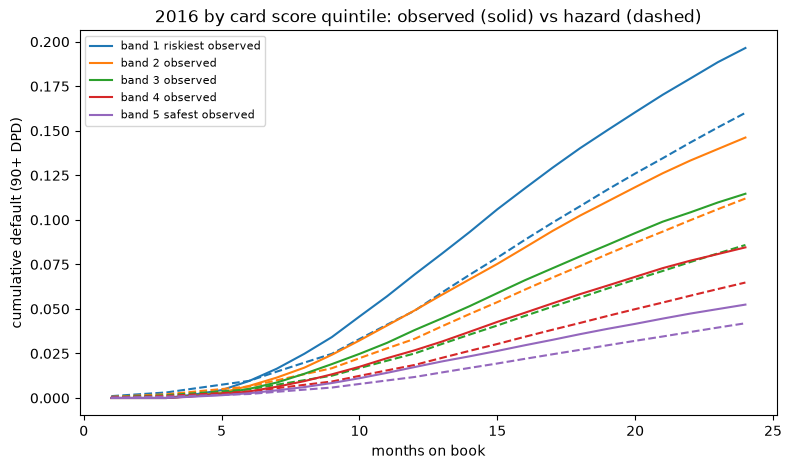

In [8]:
# Evidence — cumulative default curve by card score band: predicted (hazard) vs observed (Aalen-Johansen), 2016
oot_s = oot.assign(score=S.score(oot, card, specs)["score"])
oot_s["band"] = pd.qcut(oot_s.score.rank(method="first"), 5, labels=["1 riskiest", "2", "3", "4", "5 safest"])
pred = SV.predicted_cif_by_group(hm.cumulative_incidence(oot_s), oot_s["band"])
emp = SV.empirical_cif(oot_s, group="band")
fig, ax = plt.subplots(figsize=(9, 5))
for i, (b, d) in enumerate(emp.groupby("band", observed=True)):
    ax.plot(d.month, d.cif_default, c=f"C{i}", label=f"band {b} observed")
    p = pred[pred.band == b]; ax.plot(p.month, p.cif_default_pred, c=f"C{i}", ls="--")
ax.set_xlabel("months on book"); ax.set_ylabel("cumulative default (90+ DPD)"); ax.set_title("2016 by card score quintile: observed (solid) vs hazard (dashed)")
ax.legend(fontsize=8); plt.show()
emp.merge(pred, on=["band", "month"], how="left").to_csv(config.DOCS_DIR / "exhibits" / "cif_by_score_band_oot.csv", index=False)

### Decision AB — What the comparison means for the card

Does the hazard rank 2016 better or worse than the card (same attributes, different target construction)? Is the CIF at 24 months better calibrated to 2016 than the card's PD (the card was fitted on 2013–2014 bad rates)? Do the score bands separate early (months 6–12) or only late? Would a hazard model change any decision, or is its value monitoring (early-month incidence by band as a leading indicator for NB09)?

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**The hazard model ranks 2016 the same as the card and would change no decision. Its value is monitoring.**

- **Ranking:** the CIF at 24 months has a Gini of 0.2834 against the card's 0.2838. The difference is −0.0005 (95% CI −0.0011 to 0.0002, p = 0.17), and the rank correlation with the card's PD is 0.992.
- **Calibration:** the CIF predicts 9.27% on 2016, against 9.60% for the card and 12.06% observed. So it is not better calibrated; both under-predict 2016 by a similar shift (calibration-in-the-large 0.301 against 0.262).
- **The prepay-as-censoring version comes closer to the observed level** (11.73%, shift 0.032), but for the wrong reason. It answers "if nobody prepaid", and its slope is 0.927.
- **Early separation:** read it off the cumulative-default-by-band chart above. That chart is not summarised as a table here, so check by eye whether the bands separate by months 6–12.
- **Use for NB09:** early-month incidence by score band is a leading indicator for vintages that are not yet 24 months old.